## Работа с временными рядами
- to_datetime
- DatetimeIndex
- срезы loc
- извлечение компонент даты
- resample
- plot
- rolling
- shift, diff

### Задача:
1. Скачать данные с временными рядами с Kaggle 
2. Создать DatetimeIndex
3. Нарисовать график со срезом за 1 квартал
4. Нарисовать график с данными по понедельникам
5. Нарисовать график со средними значениями за месяц
6. Нарисовать график со скользящим средним в месяц

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df_raw = pd.read_csv('../data/raw/nvda_stock_clean.csv')

In [3]:
df_raw

,date,ticker,open,high,low,close,volume,daily_return_pct,log_return,intraday_return_pct,daily_range_pct,overnight_gap_pct,sma_20,sma_50,volatility_20_pct,volume_sma_20,drawdown_pct,year,month,day_of_week
0,1999-01-22,NVDA,0.040018,0.044663,0.035492,0.037517,2714688000,NaN,NaN,-6.249138,22.916564,NaN,NaN,NaN,NaN,NaN,0.000000,1999,1,Friday
1,1999-01-25,NVDA,0.040494,0.041923,0.037517,0.041448,510480000,10.476402,0.099632,2.353687,10.880707,7.935928,NaN,NaN,NaN,NaN,0.000000,1999,1,Monday
2,1999-01-26,NVDA,0.041923,0.042757,0.037636,0.038231,343200000,-7.759382,-0.080770,-8.805878,12.216088,1.147548,NaN,NaN,NaN,NaN,-7.759382,1999,1,Tuesday
3,1999-01-27,NVDA,0.038350,0.039303,0.036206,0.038113,244368000,-0.311020,-0.003115,-0.620124,8.075938,0.311032,NaN,NaN,NaN,NaN,-8.046269,1999,1,Wednesday
4,1999-01-28,NVDA,0.038113,0.038350,0.037755,0.037993,227520000,-0.314385,-0.003149,-0.314397,1.562383,0.000012,NaN,NaN,NaN,NaN,-8.335358,1999,1,Thursday
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
6953,2026-09-15,NVDA,213.380005,213.940002,211.160004,212.169998,88059700,0.573564,0.005719,-0.567067,1.302839,1.147136,218.613983,213.019880,45.288298,130267400.0,-9.792585,2026,9,Tuesday
6954,2026-09-16,NVDA,214.139999,216.759995,212.500000,213.899994,96563600,0.815382,0.008121,-0.112079,1.989350,0.928501,218.334263,213.363682,44.753673,129939170.0,-9.057050,2026,9,Wednesday
6955,2026-09-17,NVDA,218.380005,219.910004,217.149994,219.339996,94191300,2.543246,0.025114,0.439597,1.263856,2.094442,218.435421,213.672645,45.576451,129808870.0,-6.744147,2026,9,Thursday
6956,2026-09-18,NVDA,219.350006,222.729996,218.029999,222.270004,190287400,1.335829,0.013270,1.331205,2.142693,0.004564,218.718539,214.066978,45.774492,134700390.0,-5.498408,2026,9,Friday


In [4]:
df_raw.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6958 entries, 0 to 6957
Data columns (total 20 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   date                 6958 non-null   object 
 1   ticker               6958 non-null   object 
 2   open                 6958 non-null   float64
 3   high                 6958 non-null   float64
 4   low                  6958 non-null   float64
 5   close                6958 non-null   float64
 6   volume               6958 non-null   int64  
 7   daily_return_pct     6957 non-null   float64
 8   log_return           6957 non-null   float64
 9   intraday_return_pct  6958 non-null   float64
 10  daily_range_pct      6958 non-null   float64
 11  overnight_gap_pct    6957 non-null   float64
 12  sma_20               6939 non-null   float64
 13  sma_50               6909 non-null   float64
 14  volatility_20_pct    6938 non-null   float64
 15  volume_sma_20        6939 non-null   f

In [5]:
df = df_raw[['date', 'open', 'close']].copy()

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6958 entries, 0 to 6957
Data columns (total 3 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   date    6958 non-null   object 
 1   open    6958 non-null   float64
 2   close   6958 non-null   float64
dtypes: float64(2), object(1)
memory usage: 163.2+ KB


In [7]:
df['date'] = pd.to_datetime(df['date'])

In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6958 entries, 0 to 6957
Data columns (total 3 columns):
 #   Column  Non-Null Count  Dtype         
---  ------  --------------  -----         
 0   date    6958 non-null   datetime64[ns]
 1   open    6958 non-null   float64       
 2   close   6958 non-null   float64       
dtypes: datetime64[ns](1), float64(2)
memory usage: 163.2 KB


In [9]:
df

,date,open,close
0,1999-01-22,0.040018,0.037517
1,1999-01-25,0.040494,0.041448
2,1999-01-26,0.041923,0.038231
3,1999-01-27,0.038350,0.038113
4,1999-01-28,0.038113,0.037993
...,...,...,...
6953,2026-09-15,213.380005,212.169998
6954,2026-09-16,214.139999,213.899994
6955,2026-09-17,218.380005,219.339996
6956,2026-09-18,219.350006,222.270004


In [10]:
df = df.set_index('date')

In [11]:
df.head(2)

,open,close
date,,
1999-01-22,0.040018,0.037517
1999-01-25,0.040494,0.041448


In [12]:
df.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 6958 entries, 1999-01-22 to 2026-09-21
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   open    6958 non-null   float64
 1   close   6958 non-null   float64
dtypes: float64(2)
memory usage: 163.1 KB


In [13]:
df_raw[df_raw['date'] == '2026-09-01']['close']

6944    217.196976
Name: close, dtype: float64

In [14]:
df.loc['2026-09-01']

open     216.507744
close    217.196976
Name: 2026-09-01 00:00:00, dtype: float64

In [15]:
df_raw[
    (df_raw['date'] >= '2026-01-01') 
    & (df_raw['date'] < '2026-02-01')
][['date', 'close']]

,date,close
6778,2026-01-02,188.409134
6779,2026-01-05,187.680817
6780,2026-01-06,186.802887
6781,2026-01-07,188.668518
6782,2026-01-08,184.608017
6783,2026-01-09,184.428436
6784,2026-01-12,184.508255
6785,2026-01-13,185.376205
6786,2026-01-14,182.712448
6787,2026-01-15,186.613327


In [16]:
df.loc['2026-01']

,open,close
date,,
2026-01-02,189.396813,188.409134
2026-01-05,191.312318,187.680817
2026-01-06,190.075228,186.802887
2026-01-07,188.129785,188.668518
2026-01-08,188.668523,184.608017
2026-01-09,184.647924,184.428436
2026-01-12,182.792269,184.508255
2026-01-13,184.568099,185.376205
2026-01-14,183.889701,182.712448


In [17]:
df.loc['2025-12':'2026-01']

,open,close
date,,
2025-12-01,174.342304,179.489975
2025-12-02,181.325577,181.026306
2025-12-03,180.647226,179.160782
2025-12-04,181.195988,182.951889
2025-12-05,183.460687,181.984146
2025-12-08,182.213611,185.116821
2025-12-09,185.126796,184.538177
2025-12-10,184.538192,183.350967
2025-12-11,179.859138,180.507614


In [18]:
df.loc['2004']

,open,close
date,,
2004-01-02,0.179661,0.175926
2004-01-05,0.178594,0.181643
2004-01-06,0.181109,0.189037
2004-01-07,0.186902,0.190714
2004-01-08,0.193076,0.191400
...,...,...
2004-12-27,0.178289,0.174325
2004-12-28,0.174707,0.173410
2004-12-29,0.172877,0.174935


In [19]:
df.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 6958 entries, 1999-01-22 to 2026-09-21
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   open    6958 non-null   float64
 1   close   6958 non-null   float64
dtypes: float64(2)
memory usage: 421.1 KB


In [20]:
df.index

DatetimeIndex(['1999-01-22', '1999-01-25', '1999-01-26', '1999-01-27',
               '1999-01-28', '1999-01-29', '1999-02-01', '1999-02-02',
               '1999-02-03', '1999-02-04',
               ...
               '2026-09-08', '2026-09-09', '2026-09-10', '2026-09-11',
               '2026-09-14', '2026-09-15', '2026-09-16', '2026-09-17',
               '2026-09-18', '2026-09-21'],
              dtype='datetime64[ns]', name='date', length=6958, freq=None)

In [21]:
df.index.year

Index([1999, 1999, 1999, 1999, 1999, 1999, 1999, 1999, 1999, 1999,
       ...
       2026, 2026, 2026, 2026, 2026, 2026, 2026, 2026, 2026, 2026],
      dtype='int32', name='date', length=6958)

In [22]:
df['year'] = df.index.year
df['month'] = df.index.month
df['day'] = df.index.day
df['day_of_week'] = df.index.day_of_week
df['day_of_year'] = df.index.day_of_year
df['day_name'] = df.index.day_name()
df['quarter'] = df.index.quarter

In [23]:
df.groupby(by=['year', 'quarter'])[['close']].mean().loc['2022':'2026']

close
year quarter            
2022 1         24.974301
     2         18.797018
     3         15.749121
     4         14.614109
2023 1         21.570288
     2         33.096865
     3         44.666781
     4         46.205200
2024 1         72.272150
     2        100.818219
     3        117.798691
     4        137.467067
2025 1        126.415025
     2        125.530898
     3        173.884058
     4        185.697031
2026 1        183.036181
     2        205.205721
     3        212.652401

In [24]:
quarter_avg_close = df['close'].resample('QS').mean()

<Axes: title={'center': 'Квартальная стоимость'}, xlabel='date'>

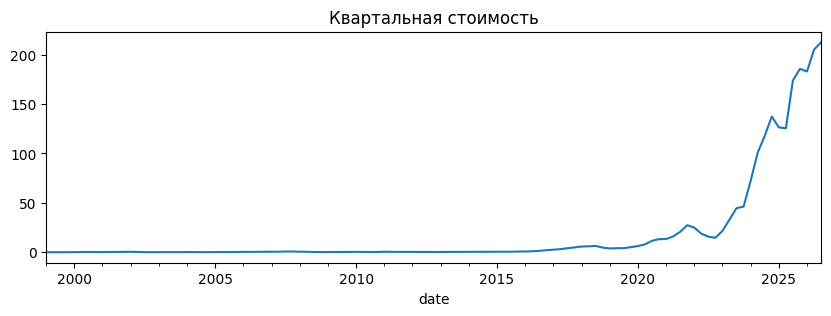

In [25]:
quarter_avg_close.plot(
    figsize=(10, 3),
    title='Квартальная стоимость'
)

<Axes: title={'center': 'Ежедневная стоимость'}, xlabel='date'>

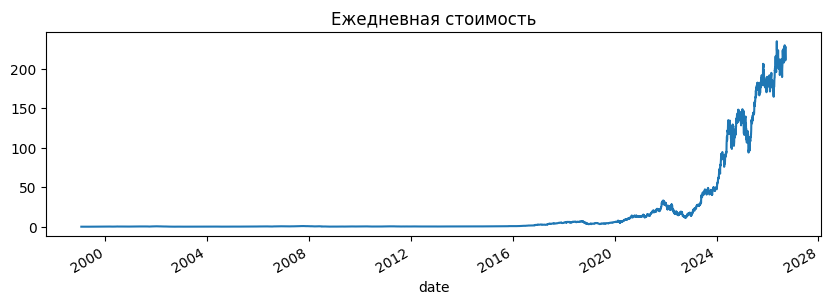

In [26]:
df['close'].plot(
    figsize=(10, 3),
    title='Ежедневная стоимость'
)

<Axes: title={'center': 'Ежедневная стоимость'}, xlabel='date'>

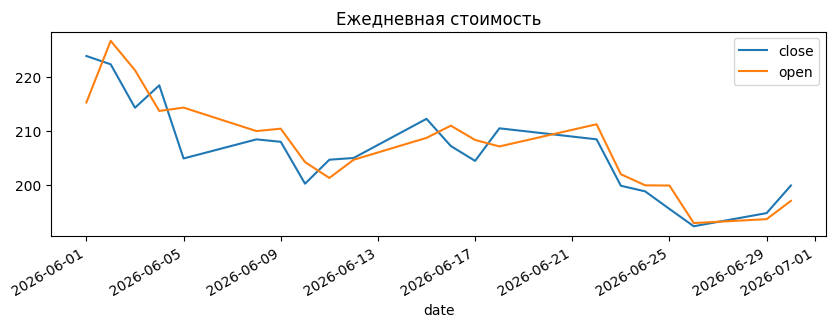

In [29]:
df[['close', 'open']].loc['2026-06'].plot(
    figsize=(10, 3),
    title='Ежедневная стоимость'
)

In [34]:
df['close_rolling_7_mean'] = df['close'].rolling(window=7).mean()

In [35]:
df

,open,close,year,month,day,day_of_week,day_of_year,day_name,quarter,close_rolling_7_mean
date,,,,,,,,,,
1999-01-22,0.040018,0.037517,1999,1,22,4,22,Friday,1,NaN
1999-01-25,0.040494,0.041448,1999,1,25,0,25,Monday,1,NaN
1999-01-26,0.041923,0.038231,1999,1,26,1,26,Tuesday,1,NaN
1999-01-27,0.038350,0.038113,1999,1,27,2,27,Wednesday,1,NaN
1999-01-28,0.038113,0.037993,1999,1,28,3,28,Thursday,1,NaN
...,...,...,...,...,...,...,...,...,...,...
2026-09-15,213.380005,212.169998,2026,9,15,1,258,Tuesday,3,219.825745
2026-09-16,214.139999,213.899994,2026,9,16,2,259,Wednesday,3,217.511097
2026-09-17,218.380005,219.339996,2026,9,17,3,260,Thursday,3,216.634284


<Axes: title={'center': 'close со скользящей средней стоимостю'}, xlabel='date'>

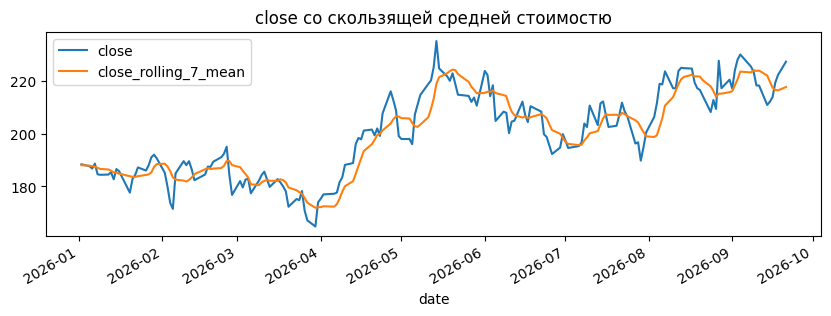

In [39]:
df[['close', 'close_rolling_7_mean']].loc['2026'].plot(
    figsize=(10, 3),
    title='close со скользящей средней стоимостю'
)

In [42]:
df['close_lag_7'] = df['close'].shift(7)

In [47]:
df['close_diff_7'] = df['close'].diff(7)

In [49]:
df[['close', 'close_lag_7', 'close_diff_7']].loc['2025-09']

,close,close_lag_7,close_diff_7
date,,,
2025-09-02,170.362213,174.551941,-4.189728
2025-09-03,170.202606,177.554596,-7.351990
2025-09-04,171.240082,179.370132,-8.130051
2025-09-05,166.611404,181.325333,-14.713928
2025-09-08,167.898254,181.155746,-13.257492
2025-09-09,170.342255,179.729233,-9.386978
2025-09-10,176.896194,173.753906,3.142288
2025-09-11,176.746552,170.362213,6.384338
2025-09-12,177.395004,170.202606,7.192398
